# 01 Conhecer e validar os dados

Este notebook apresenta a base Home Credit e verifica a qualidade do recorte
que será utilizado no desafio: **20.000 solicitações, dez variáveis,
um identificador e o alvo**. Não treinamos modelos nem alteramos os CSVs aqui.

**Sequência:** 01 conhecer e validar → 02 limpar, normalizar e treinar →
03 propor a solução e a estratégia do Tech Challenge.

Os dados de origem são `application_train.csv` e
`HomeCredit_columns_description.csv`, já disponíveis em
`data/raw/home-credit-default-risk/`. As tabelas auxiliares da competição
não são necessárias. Execute as células de cima para baixo.

## 1 Ambiente e arquivos utilizados

Use o ambiente do projeto (`make notebook`) ou o Jupyter do Docker.
O notebook não faz download nem autenticação no Kaggle.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

In [2]:
project_root = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "requirements.txt").is_file()
        and (folder / "notebooks").is_dir()
        and (folder / "ml_prep_kit").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Abra o notebook dentro da pasta do projeto.")

raw_path = project_root / "data" / "raw" / "home-credit-default-risk"
train_file = raw_path / "application_train.csv"
if not train_file.is_file():
    raise FileNotFoundError(f"Arquivo de treinamento não encontrado: {train_file}")

description_file = raw_path / "HomeCredit_columns_description.csv"
if not description_file.is_file():
    raise FileNotFoundError(f"Dicionário não encontrado: {description_file}")

pd.DataFrame(
    [
        {"arquivo": path.name, "tamanho_mb": round(path.stat().st_size / 1e6, 2)}
        for path in [train_file, description_file]
    ]
)

,arquivo,tamanho_mb
0,application_train.csv,166.13
1,HomeCredit_columns_description.csv,0.04


## 2 Recorte escolhido e significado das variáveis

`SK_ID_CURR` serve para rastreabilidade e nunca será uma feature.
`TARGET = 1` indica dificuldade de pagamento; `0` representa os demais casos.
O dicionário não revela os limites de dias e parcelas usados para construir
esse alvo, portanto não o interpretaremos como inadimplência em 30 ou 90 dias.

A idade está em dias negativos, relativos à solicitação. A renda e a anuidade
não serão chamadas de valores mensais, anuais ou em reais sem confirmação
dessa informação na documentação da fonte.

Mantemos idade, renda, valor do crédito, anuidade, tipo de renda, escolaridade,
moradia, filhos, posse de carro e posse de imóvel. A seleção é fixa;
não faremos seleção de features usando resultados do conjunto de teste.

In [3]:
RANDOM_STATE = 42
SAMPLE_SIZE = 20_000
SELECTED_COLUMNS = [
    "SK_ID_CURR",
    "TARGET",
    "DAYS_BIRTH",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "CNT_CHILDREN",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
]

source_columns = pd.read_csv(train_file, nrows=0).columns
missing_columns = set(SELECTED_COLUMNS).difference(source_columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes: {sorted(missing_columns)}")

raw_df = pd.read_csv(train_file, usecols=SELECTED_COLUMNS)[SELECTED_COLUMNS]
if raw_df["SK_ID_CURR"].isna().any() or raw_df["SK_ID_CURR"].duplicated().any():
    raise ValueError("A base precisa ter identificadores preenchidos e únicos.")
if raw_df["TARGET"].isna().any() or set(raw_df["TARGET"].unique()) != {0, 1}:
    raise ValueError("TARGET deve conter as duas classes 0 e 1, sem nulos.")
if len(raw_df) < SAMPLE_SIZE:
    raise ValueError(f"São necessários pelo menos {SAMPLE_SIZE:,} registros.")

if len(raw_df) == SAMPLE_SIZE:
    sample_df = raw_df.copy()
else:
    sample_df, _ = train_test_split(
        raw_df,
        train_size=SAMPLE_SIZE,
        stratify=raw_df["TARGET"],
        random_state=RANDOM_STATE,
    )
sample_df = sample_df.sort_values("SK_ID_CURR").reset_index(drop=True)

In [4]:
descriptions = pd.read_csv(description_file, encoding="cp1252")
selected_descriptions = descriptions.loc[
    descriptions["Table"].str.contains("application_{", regex=False)
    & descriptions["Row"].isin(SELECTED_COLUMNS),
    ["Row", "Description", "Special"],
].rename(columns={"Row": "coluna", "Description": "descrição"})
display(selected_descriptions.reset_index(drop=True))
display(
    pd.DataFrame(
        [
            {
                "conjunto": "origem",
                "linhas": len(raw_df),
                "colunas": len(source_columns),
            },
            {
                "conjunto": "recorte",
                "linhas": len(sample_df),
                "colunas": len(sample_df.columns),
            },
        ]
    )
)

,coluna,descrição,Special
0,SK_ID_CURR,ID of loan in our sample,NaN
1,TARGET,Target variable (1 - client with payment diffi...,NaN
2,FLAG_OWN_CAR,Flag if the client owns a car,NaN
3,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
4,CNT_CHILDREN,Number of children the client has,NaN
5,AMT_INCOME_TOTAL,Income of the client,NaN
6,AMT_CREDIT,Credit amount of the loan,NaN
7,AMT_ANNUITY,Loan annuity,NaN
8,NAME_INCOME_TYPE,"Clients income type (businessman, working, mat...",NaN
9,NAME_EDUCATION_TYPE,Level of highest education the client achieved,NaN


,conjunto,linhas,colunas
0,origem,307511,122
1,recorte,20000,12


## 3 Amostragem e variável alvo

A amostra é estratificada por `TARGET`, com seed 42, e preserva aproximadamente
a proporção das classes. O segundo notebook repetirá exatamente essa seleção
antes de separar treino, validação, teste e produção simulada.

Esta visão caracteriza a base; as métricas do modelo serão calculadas
separadamente, sem ajustar o modelo a partir do teste ou da produção.

quantidade  percentual
conjunto TARGET                        
origem   0           282686       91.93
         1            24825        8.07
amostra  0            18385       91.92
         1             1615        8.08

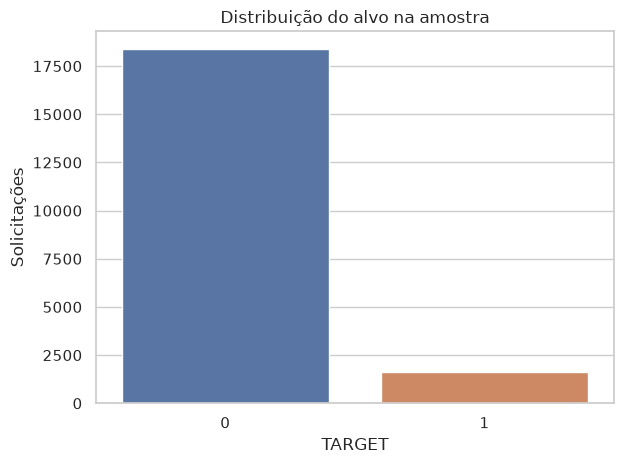

In [5]:
target_summary = pd.concat(
    {
        name: frame["TARGET"].value_counts().sort_index().rename("quantidade")
        for name, frame in {"origem": raw_df, "amostra": sample_df}.items()
    },
    names=["conjunto", "TARGET"],
).to_frame()
target_summary["percentual"] = (
    target_summary["quantidade"]
    / target_summary.groupby(level="conjunto")["quantidade"].transform("sum")
    * 100
).round(2)
display(target_summary)

sns.countplot(data=sample_df, x="TARGET", hue="TARGET", legend=False)
plt.title("Distribuição do alvo na amostra")
plt.ylabel("Solicitações")
plt.tight_layout()
plt.show()

## 4 Tipos, ausências e duplicidades

Nulos não serão preenchidos durante a análise. Primeiro identificamos onde
existem e decidimos o tratamento. No treino, a anuidade ausente poderá ser
imputada pela mediana aprendida exclusivamente no conjunto de treinamento.

In [6]:
quality_summary = pd.DataFrame(
    {
        "tipo": raw_df.dtypes.astype(str),
        "nulos_origem": raw_df.isna().sum(),
        "nulos_amostra": sample_df.isna().sum(),
        "percentual_nulos_origem": raw_df.isna().mean().mul(100).round(4),
        "valores_distintos_amostra": sample_df.nunique(dropna=False),
    }
)
display(quality_summary)
display(
    pd.DataFrame(
        [
            {
                "conjunto": name,
                "linhas_duplicadas": int(frame.duplicated().sum()),
                "ids_duplicados": int(frame["SK_ID_CURR"].duplicated().sum()),
            }
            for name, frame in {"origem": raw_df, "amostra": sample_df}.items()
        ]
    )
)

,tipo,nulos_origem,nulos_amostra,percentual_nulos_origem,valores_distintos_amostra
SK_ID_CURR,int64,0,0,0.0000,20000
TARGET,int64,0,0,0.0000,2
DAYS_BIRTH,int64,0,0,0.0000,11514
AMT_INCOME_TOTAL,float64,0,0,0.0000,429
AMT_CREDIT,float64,0,0,0.0000,2454
AMT_ANNUITY,float64,12,2,0.0039,6012
NAME_INCOME_TYPE,object,0,0,0.0000,8
NAME_EDUCATION_TYPE,object,0,0,0.0000,5
NAME_HOUSING_TYPE,object,0,0,0.0000,6
CNT_CHILDREN,int64,0,0,0.0000,8


,conjunto,linhas_duplicadas,ids_duplicados
0,origem,0,0
1,amostra,0,0


## 5 Validações iniciais de domínio

As verificações abaixo são diagnósticos explícitos em pandas. O contrato
formal em Pandera e a demonstração de bloqueio de um lote inválido serão
parte da estratégia do notebook 03; este diagnóstico não substitui essa entrega.

Adotamos idade de 18 a 100 anos como regra inicial do experimento,
valores de crédito e renda positivos, filhos inteiros não negativos e
flags `Y/N`. A idade é calculada apenas para validar e visualizar a base.

In [7]:
age_years = -raw_df["DAYS_BIRTH"] / 365.25
domain_checks = {
    "Idade entre 18 e 100 anos": age_years.between(18, 100),
    "Renda positiva e finita": (
        raw_df["AMT_INCOME_TOTAL"].gt(0) & np.isfinite(raw_df["AMT_INCOME_TOTAL"])
    ),
    "Crédito positivo e finito": (
        raw_df["AMT_CREDIT"].gt(0) & np.isfinite(raw_df["AMT_CREDIT"])
    ),
    "Anuidade positiva ou ausente": (
        raw_df["AMT_ANNUITY"].isna()
        | (raw_df["AMT_ANNUITY"].gt(0) & np.isfinite(raw_df["AMT_ANNUITY"]))
    ),
    "Filhos inteiros não negativos": (
        raw_df["CNT_CHILDREN"].ge(0) & raw_df["CNT_CHILDREN"].mod(1).eq(0)
    ),
    "Posse de carro em Y/N": raw_df["FLAG_OWN_CAR"].isin(["Y", "N"]),
    "Posse de imóvel em Y/N": raw_df["FLAG_OWN_REALTY"].isin(["Y", "N"]),
}
for column in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_HOUSING_TYPE"]:
    domain_checks[f"{column} preenchida"] = raw_df[column].notna() & raw_df[
        column
    ].astype("string").str.strip().ne("").fillna(False)
validation_report = pd.DataFrame(
    [
        {"regra": rule, "violações": int((~valid.fillna(False)).sum())}
        for rule, valid in domain_checks.items()
    ]
)
validation_report["status"] = np.where(
    validation_report["violações"].eq(0), "OK", "INVESTIGAR"
)
display(validation_report)

,regra,violações,status
0,Idade entre 18 e 100 anos,0,OK
1,Renda positiva e finita,0,OK
2,Crédito positivo e finito,0,OK
3,Anuidade positiva ou ausente,0,OK
4,Filhos inteiros não negativos,0,OK
5,Posse de carro em Y/N,0,OK
6,Posse de imóvel em Y/N,0,OK
7,NAME_INCOME_TYPE preenchida,0,OK
8,NAME_EDUCATION_TYPE preenchida,0,OK
9,NAME_HOUSING_TYPE preenchida,0,OK


## 6 Distribuições e valores extremos

As descrições são calculadas na amostra. Valores extremos são sinalizados
para interpretação, sem remoção automática. A escala logarítmica do gráfico
de renda serve somente à visualização e não modifica os dados.

,count,mean,std,min,1%,50%,95%,99%,max
AMT_INCOME_TOTAL,20000.0,168052.175561,95258.001945,27000.000000,45000.000000,144000.000000,3.375000e+05,4.950000e+05,2.250000e+06
AMT_CREDIT,20000.0,599871.700800,404098.659443,45000.000000,76410.000000,513531.000000,1.350000e+06,1.831898e+06,3.312162e+06
AMT_ANNUITY,19998.0,27103.990774,14525.924103,2920.500000,6174.000000,25033.500000,5.326672e+04,7.123500e+04,2.250000e+05
CNT_CHILDREN,20000.0,0.419600,0.733868,0.000000,0.000000,0.000000,2.000000e+00,3.000000e+00,1.900000e+01
AGE_YEARS,20000.0,43.745993,11.994509,21.026694,22.655715,42.945927,6.343053e+01,6.674352e+01,6.893908e+01


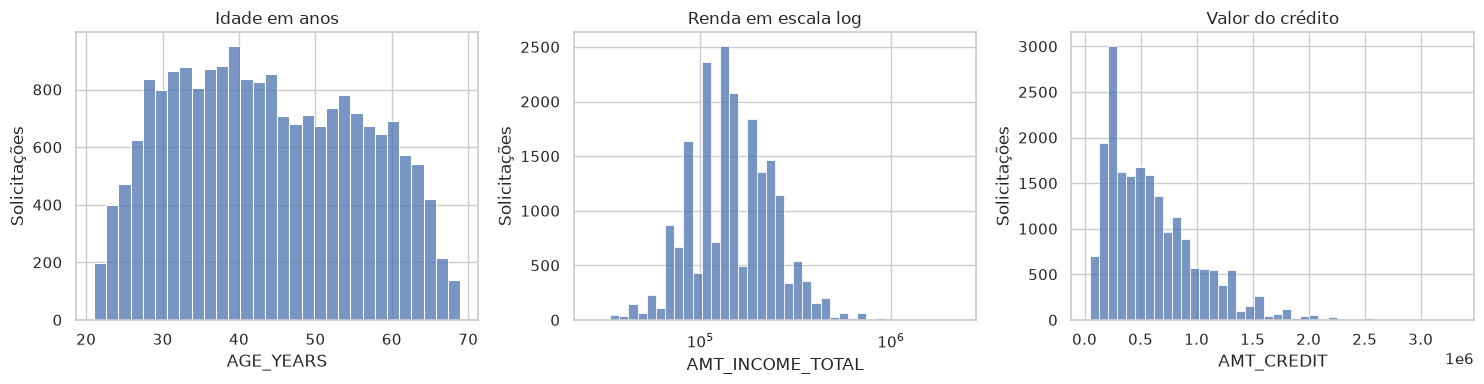

In [8]:
numeric_columns = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "CNT_CHILDREN"]
numeric_view = sample_df[numeric_columns].assign(
    AGE_YEARS=-sample_df["DAYS_BIRTH"] / 365.25
)
display(numeric_view.describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(numeric_view, x="AGE_YEARS", bins=30, ax=axes[0])
sns.histplot(numeric_view, x="AMT_INCOME_TOTAL", log_scale=True, bins=40, ax=axes[1])
sns.histplot(numeric_view, x="AMT_CREDIT", bins=40, ax=axes[2])
for ax, title in zip(
    axes, ["Idade em anos", "Renda em escala log", "Valor do crédito"], strict=True
):
    ax.set_title(title)
    ax.set_ylabel("Solicitações")
plt.tight_layout()
plt.show()

## 7 Categorias e representatividade

Categorias pouco frequentes podem desaparecer na amostragem. Isso precisa
aparecer na interpretação: o baseline não demonstrará desempenho confiável
para todos os segmentos. Categorias novas serão toleradas pelo encoder,
mas deverão ser monitoradas como possível mudança de perfil.

In [9]:
categorical_columns = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
]
category_tables = []
for column in categorical_columns:
    counts = (
        pd.concat(
            [
                raw_df[column].value_counts(dropna=False).rename("origem"),
                sample_df[column].value_counts(dropna=False).rename("amostra"),
            ],
            axis=1,
        )
        .fillna(0)
        .astype(int)
    )
    counts.index.name = "categoria"
    category_tables.append(counts.reset_index().assign(coluna=column))
category_summary = pd.concat(category_tables, ignore_index=True)
display(category_summary[["coluna", "categoria", "origem", "amostra"]])

,coluna,categoria,origem,amostra
0,NAME_INCOME_TYPE,Working,158774,10197
1,NAME_INCOME_TYPE,Commercial associate,71617,4710
2,NAME_INCOME_TYPE,Pensioner,55362,3623
3,NAME_INCOME_TYPE,State servant,21703,1464
4,NAME_INCOME_TYPE,Unemployed,22,1
5,NAME_INCOME_TYPE,Student,18,3
6,NAME_INCOME_TYPE,Businessman,10,1
7,NAME_INCOME_TYPE,Maternity leave,5,1
8,NAME_EDUCATION_TYPE,Secondary / secondary special,218391,14151
9,NAME_EDUCATION_TYPE,Higher education,74863,4856


## 8 Conclusão e passagem para o treinamento

A base representa solicitações com dificuldade de pagamento como classe
minoritária. Os próximos passos são converter idade e flags, manter uma
política explícita de ausências e separar os conjuntos antes de aprender
qualquer transformação.

Não há uma data de calendário que estabeleça períodos reais de produção.
O notebook 03 proporá janelas simuladas e explicará seus limites.
Idade, escolaridade e outras variáveis também exigirão discussão de vieses.

O diagnóstico abaixo deve ser revisado antes de continuar. Nenhum dado
tratado, modelo ou relatório de drift foi criado neste notebook.

In [10]:
display(
    pd.Series(
        {
            "linhas_na_amostra": len(sample_df),
            "features": len(SELECTED_COLUMNS) - 2,
            "positivos_na_amostra": int(sample_df["TARGET"].sum()),
            "nulos_na_amostra": int(sample_df.isna().sum().sum()),
            "violações_de_domínio_na_origem": int(validation_report["violações"].sum()),
        },
        name="resumo",
    )
)
if validation_report["violações"].gt(0).any():
    raise ValueError("Revise as violações de domínio antes do notebook 02.")
print("Diagnóstico concluído. Continue no notebook 02.")

linhas_na_amostra                 20000
features                             10
positivos_na_amostra               1615
nulos_na_amostra                      2
violações_de_domínio_na_origem        0
Name: resumo, dtype: int64

Diagnóstico concluído. Continue no notebook 02.
